# Custom CNN:

### Data:

In [115]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

# Parameters
img_size = (128, 128) # Standard for Intel dataset
batch_size = 32

# Load Datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    './dataset/seg_train/seg_train',
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    './dataset/seg_test/seg_test',
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)


# EDA: Check Class Balance
class_names = train_ds.class_names
print(f"Classes: {class_names}")

# Normalize (0-1) using a Rescaling layer
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))




Found 14034 files belonging to 6 classes.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


### Model:

i tried many models and finally stopped at this one because i realized that i would need much more compuational power if i wanted to geniunely make a good (>85% accuracy) model, i found the approach of using multiples of 16 between layers instead of doubling it helped with overfitting while increasing accuracy however some dropout and BN and residual layers was still needed, pooling was done in alternation to avoid shrinking the data volume too much and losing feature information.

In [116]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2), # Rotations help with mountain angles
    layers.RandomZoom(0.2),     # Zooms help distinguish textures
    layers.RandomContrast(0.2), # Helps with different lighting in scenes
])
       
def residual_block(x, filters):
    shortcut = x
    # First Conv
    x = layers.SeparableConv2D(filters, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    # Second Conv
    x = layers.SeparableConv2D(filters, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)

    # Add back the shortcut
    # If filter counts don't match, we use a 1x1 conv to align them
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), padding='same')(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    return x

def build_deep_custom_cnn():
    inputs = layers.Input(shape=(128, 128, 3))
    x = data_augmentation(inputs)

    # Initial Feature Extraction
    x = layers.Conv2D(16, (5, 5), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)

    # Use a loop to add depth without code clutter
    # This maintains your 16-increment rule
    filter_list = [32, 48, 64, 80, 96, 112]

    for f in filter_list:
        # We use the Residual logic here
        shortcut = layers.Conv2D(f, (1, 1), strides=(2, 2) if f % 32 == 0 else (1, 1))(x)

        x = layers.SeparableConv2D(f, (3, 3), padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)

        if f % 32 == 0: # Downsample every other block
            x = layers.MaxPooling2D((2, 2))(x)

        if f <= 80 :
             x = layers.Dropout(0.3)(x)
        else:
             x = layers.Dropout(0.5)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(6, activation='softmax')(x)

    return models.Model(inputs, outputs)



custom_model = build_deep_custom_cnn()
custom_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

i ran the model on colab and downloaded it so i could manipulate it on my device (i did not have enough runtime to make the full project on colab)

In [118]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Common Callbacks for both models
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
lr_adj = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

# --- TRAIN CUSTOM CNN ---
# print("Starting Custom CNN Training...")
# history_custom = custom_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=20,
#     batch_size=32,
#     callbacks=[early_stop, lr_adj]
# )
# this was done on google colab and the resulting model and training history will now be loaded from files

import pickle
import pandas as pd

# Load the pickle file
with open('train_history.pkl', 'rb') as f:
    history_data = pickle.load(f)

# 1. Print raw keys (this shows what metrics were tracked, e.g., 'loss', 'accuracy')
print("Metrics tracked:", history_data.keys())

# 2. Print final values (to see how the model ended up)
print("\nFinal Epoch Results:")
for metric, values in history_data.items():
    print(f"{metric}: {values[-1]:.4f}")

# 3. View as a nice table (optional but helpful)
history_df = pd.DataFrame(history_data)
print("\nEpochs of training:")
print(history_df)


# Load the model
# Load only the learned weights
custom_model.load_weights('intel_custom_cnn_v1(2).h5')

# 1. Print the architecture (Layers, shapes, and parameters)
print("\n--- Model Summary ---")
custom_model.summary()

# 2. Print Input and Output shapes
print(f"\nInput Shape: {custom_model.input_shape}")
print(f"Number of Classes: {custom_model.output_shape[-1]}")


Metrics tracked: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])

Final Epoch Results:
accuracy: 0.7669
loss: 0.6445
val_accuracy: 0.7083
val_loss: 0.9141
learning_rate: 0.0005

Epochs of training:
    accuracy      loss  val_accuracy  val_loss  learning_rate
0   0.509049  1.222845      0.249667  3.023482         0.0010
1   0.604461  1.025600      0.474333  1.870272         0.0010
2   0.639590  0.951074      0.549000  1.295838         0.0010
3   0.664672  0.898486      0.586333  1.290646         0.0010
4   0.685336  0.846789      0.603000  1.122299         0.0010
5   0.704218  0.808023      0.594000  1.335500         0.0010
6   0.717116  0.774703      0.707333  0.835624         0.0010
7   0.725096  0.750963      0.522000  1.928108         0.0010
8   0.736212  0.733837      0.714000  0.937626         0.0010
9   0.739276  0.706734      0.553333  1.825212         0.0010
10  0.766282  0.656535      0.710000  0.926554         0.0005
11  0.767066  0.651336      0

as we can see the model is bad-mediocre and caps at 76% with some overfitting even though.
i kept making it deeper and adding reguliarization to combat overfitting but this is the best i could do in around 4 hours of work.

# Pre-Trained Model:

### Data:

the data for the custom cnn was normalized before the model was used however the pretrained model normalizes the data itself (it needs to range from -1 to 1 instead of 0 to 1 like the custom model) so i reimported the data (inefficient but for a small dataset not that big of a deal).

In [ ]:
# # Parameters
# img_size = (128, 128) # Standard for Intel dataset
# batch_size = 32

# # Load Datasets
# train_ds = tf.keras.utils.image_dataset_from_directory(
#     './dataset/seg_train/seg_train',
#     image_size=img_size,
#     batch_size=batch_size,
#     label_mode='categorical'
# )

# val_ds = tf.keras.utils.image_dataset_from_directory(
#     './dataset/seg_test/seg_test',
#     image_size=img_size,
#     batch_size=batch_size,
#     label_mode='categorical'
# )


### Model:

i loaded the mobilenetv2 model and added a layer of 128 to train it to our data, i found that not adding a layer didnt give good accuracy and adding it also helped avoid having to unfreeze the models layers which are bigger than 128. i also added some data augmentation to avoid overfitting.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras import layers, models, optimizers, regularizers

# --- 1. Define the Augmentation Layer ---
# This layer is only active during training! It automatically turns off during .evaluate()
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    # layers.RandomZoom(0.2),
    # layers.RandomTranslation(0.1, 0.1),
])

# --- 2. Load pre-trained MobileNetV2 ---
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False 

# --- 3. Build the Pipeline ---
inputs = layers.Input(shape=(128, 128, 3))

# Step A: Apply Augmentation FIRST
x = data_augmentation(inputs)

# Step B: Preprocess for MobileNetV2 (scaling to [-1, 1])
x = tf.keras.applications.mobilenet_v2.preprocess_input(x) 

# Step C: Pass through the base model
x = base_model(x, training=False) 

# Step D: Custom Head
x = layers.GlobalAveragePooling2D()(x)

# 1. Add an intermediate layer to "process" the 1280 features
x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
x = layers.Dropout(0.3)(x)

# 3. Output
outputs = layers.Dense(6, activation='softmax')(x)



i also ran this model on colab and downloaded it

In [ ]:
tl_model = models.Model(inputs, outputs)


# # EDA: Check Class Balance
# class_names = train_ds.class_names
# print(f"Classes: {class_names}")


# tl_model.compile(
#     optimizer=optimizers.Adam(learning_rate=0.0001), 
#     loss='categorical_crossentropy', 
#     metrics=['accuracy']
# )

# # Common Callbacks for both models
# early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
# lr_adj = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-8, verbose=1)

# # --- TRAIN MOBILENETV2 (Transfer Learning) ---
# print("\nStarting MobileNetV2 Training...")
# history_tl = tl_model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=20,
#     batch_size=32,
#     callbacks=[early_stop, lr_adj])


import pickle
import pandas as pd

# Load the pickle file
with open('mobilenet_history.pkl', 'rb') as f:
    history_data = pickle.load(f)

# 1. Print raw keys (this shows what metrics were tracked, e.g., 'loss', 'accuracy')
print("Metrics tracked:", history_data.keys())

# 2. Print final values (to see how the model ended up)
print("\nFinal Epoch Results:")
for metric, values in history_data.items():
    print(f"{metric}: {values[-1]:.4f}")

# 3. View as a nice table (optional but helpful)
history_df = pd.DataFrame(history_data)
print("\nEpochs of training:")
print(history_df)


# Load the model
tl_model.load_weights('mobilenet.h5')

# 1. Print the architecture of the CORRECT model
print("\n--- MobileNet Transfer Model Summary ---")
tl_model.summary()

# 2. Print Input and Output shapes
print(f"\nInput Shape: {tl_model.input_shape}")
print(f"Number of Classes: {tl_model.output_shape[-1]}")



Metrics tracked: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])

Final Epoch Results:
accuracy: 0.8856
loss: 0.4001
val_accuracy: 0.9073
val_loss: 0.3443
learning_rate: 0.0001

Epochs of training:
    accuracy      loss  val_accuracy  val_loss  learning_rate
0   0.705501  2.817897      0.871333  2.132630         0.0001
1   0.826422  1.990631      0.891333  1.628485         0.0001
2   0.850791  1.559494      0.888000  1.299708         0.0001
3   0.858558  1.266602      0.899000  1.058947         0.0001
4   0.866681  1.052592      0.902333  0.884442         0.0001
5   0.869246  0.896278      0.903000  0.756867         0.0001
6   0.873094  0.782767      0.905667  0.667222         0.0001
7   0.873308  0.702771      0.907333  0.596939         0.0001
8   0.874662  0.637177      0.904000  0.544781         0.0001
9   0.878296  0.587981      0.902333  0.505046         0.0001
10  0.880291  0.541452      0.907333  0.464024         0.0001
11  0.884922  0.505602      0

as we can see the accuracy is much higher and there is no overfitting at all in fact validation accuracy is higher than training accuracy which means the model is very well generalized

Found 14034 files belonging to 6 classes.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


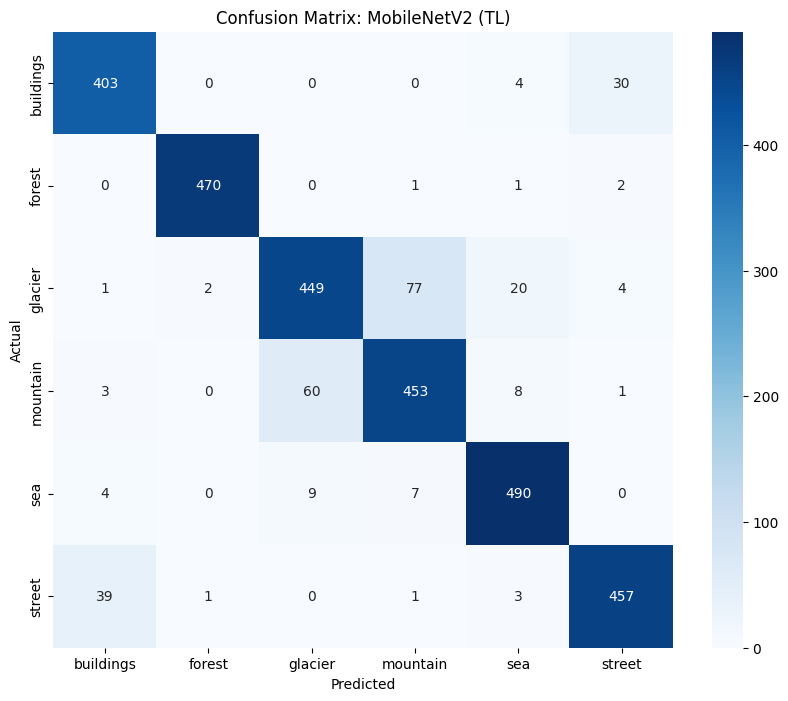


Classification Report for MobileNetV2 (TL):
              precision    recall  f1-score   support

   buildings       0.90      0.92      0.91       437
      forest       0.99      0.99      0.99       474
     glacier       0.87      0.81      0.84       553
    mountain       0.84      0.86      0.85       525
         sea       0.93      0.96      0.95       510
      street       0.93      0.91      0.92       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



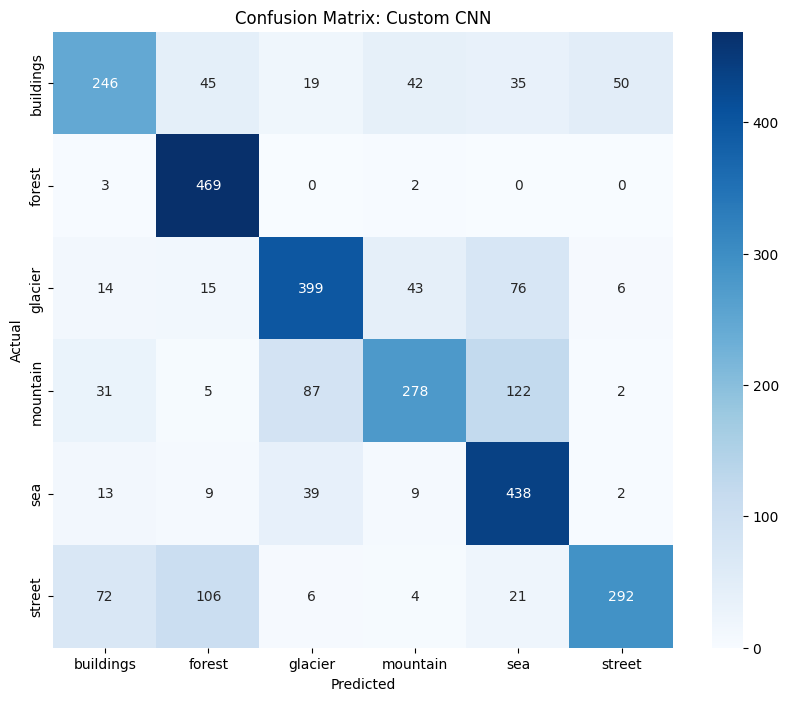


Classification Report for Custom CNN:
              precision    recall  f1-score   support

   buildings       0.65      0.56      0.60       437
      forest       0.72      0.99      0.84       474
     glacier       0.73      0.72      0.72       553
    mountain       0.74      0.53      0.62       525
         sea       0.63      0.86      0.73       510
      street       0.83      0.58      0.68       501

    accuracy                           0.71      3000
   macro avg       0.72      0.71      0.70      3000
weighted avg       0.72      0.71      0.70      3000



In [122]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

def analyze_model_performance(model, dataset, model_name):
    # 1. Get all predictions and true labels
    all_labels = []
    all_preds = []
    
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        all_labels.extend(np.argmax(labels.numpy(), axis=1))
        all_preds.extend(np.argmax(preds, axis=1))
    
    # 2. Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    # 3. Print F1-Scores
    print(f"\nClassification Report for {model_name}:")
    print(classification_report(all_labels, all_preds, target_names=class_names))


# Parameters
img_size = (128, 128) # Standard for Intel dataset
batch_size = 32

# Load Datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    './dataset/seg_train/seg_train',
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    './dataset/seg_test/seg_test',
    image_size=img_size,
    batch_size=batch_size,
    label_mode='categorical'
)


# EDA: Check Class Balance
class_names = train_ds.class_names
print(f"Classes: {class_names}")


# Run analysis for both
analyze_model_performance(tl_model, val_ds, "MobileNetV2 (TL)")


# Normalize (0-1) using a Rescaling layer
normalization_layer = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))


analyze_model_performance(custom_model, val_ds, "Custom CNN")


the custom model struggles with a lot more classifications than the pre-trained model.

# Visualization of an example image's feature maps

1/1 [==============================] - 0s 239ms/step


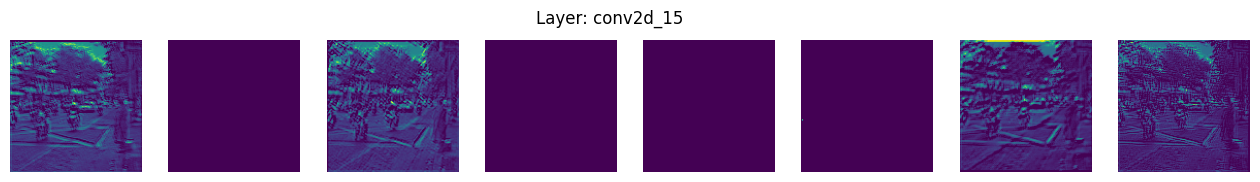

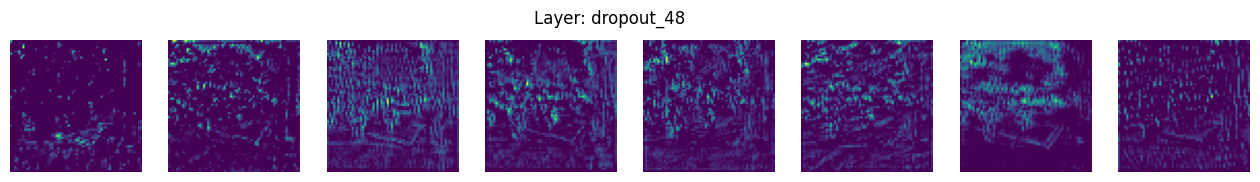

In [123]:
def visualize_features(model, img_path, layer_names):
    # Load and preprocess a single image
    img = tf.keras.utils.load_img(img_path, target_size=(128, 128))
    img_tensor = tf.keras.utils.img_to_array(img)
    img_tensor = np.expand_dims(img_tensor, axis=0)
    img_tensor /= 255.0  # Match the 1./255 scaling used in your custom_model

    # Create a model that outputs the activation maps
    outputs = [model.get_layer(name).output for name in layer_names]
    visualization_model = models.Model(inputs=model.input, outputs=outputs)
    
    activations = visualization_model.predict(img_tensor)

    for layer_name, layer_activation in zip(layer_names, activations):
        n_features = layer_activation.shape[-1]
        size = layer_activation.shape[1]
        
        # Display the first 8 filters of the layer
        n_cols = 8
        plt.figure(figsize=(16, 2))
        plt.suptitle(f"Layer: {layer_name}")
        for i in range(n_cols):
            plt.subplot(1, n_cols, i + 1)
            plt.imshow(layer_activation[0, :, :, i], cmap='viridis')
            plt.axis('off')
        plt.show()

# Example: Visualize the first Conv layer and a later one from your custom_model
# Get names from custom_model.summary()
target_layers = [custom_model.layers[2].name, custom_model.layers[10].name] 
# Replace 'test_img.jpg' with a path to an actual image file in your Colab
visualize_features(custom_model, './dataset/seg_pred/seg_pred/3.jpg', target_layers)